In [1]:
# ============================================================
# CUSTOMER REVIEW SENTIMENT CLASSIFIER (NLP)
# Models: Logistic Regression and Multinomial Naive Bayes
# Features: Text cleaning, TF-IDF, evaluation, error analysis
# ============================================================

%pip install -q pandas numpy matplotlib seaborn scikit-learn nltk joblib

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Customer Review Sentiment Classifier")
print("=" * 55)

Note: you may need to restart the kernel to use updated packages.
Customer Review Sentiment Classifier


In [3]:

# Part 2: Load the Dataset

import nltk

nltk.download("movie_reviews")

from nltk.corpus import movie_reviews

reviews = []
sentiments = []

for category in movie_reviews.categories():
    for file_id in movie_reviews.fileids(category):
        review = movie_reviews.raw(file_id)
        reviews.append(review)
        sentiments.append(category)

df = pd.DataFrame({
    "review": reviews,
    "sentiment": sentiments
})

print("Dataset loaded successfully!")
print("Total reviews:", len(df))

print("\nFirst 5 rows:")
display(df.head())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())


[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\movie_reviews.zip.


Dataset loaded successfully!
Total reviews: 2000

First 5 rows:


,review,sentiment
0,"plot : two teen couples go to a church party ,...",neg
1,the happy bastard's quick movie review \ndamn ...,neg
2,it is movies like these that make a jaded movi...,neg
3,""" quest for camelot "" is warner bros . ' firs...",neg
4,synopsis : a mentally unstable man undergoing ...,neg



Sentiment distribution:
sentiment
neg    1000
pos    1000
Name: count, dtype: int64


In [5]:

# Part 3: Text Cleaning

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply cleaning to every review
df["clean_review"] = df["review"].apply(clean_text)

# Display original and cleaned reviews
print("Original review:")
print(df["review"].iloc[0][:300])

print("\nCleaned review:")
print(df["clean_review"].iloc[0][:300])

print("\nText cleaning completed!")


Original review:
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the

Cleaned review:
plot two teen couples go to a church party drink and then drive they get into an accident one of the guys dies but his girlfriend continues to see him in her life and has nightmares what s the deal watch the movie and sorta find out critique a mind fuck movie for the teen generation that touches on 

Text cleaning completed!


Dataset shape: (2000, 3)

Missing values:
review          0
sentiment       0
clean_review    0
dtype: int64

Sentiment counts:
sentiment
neg    1000
pos    1000
Name: count, dtype: int64

Review length statistics:
count    2000.000000
mean      665.636000
std       293.734355
min        17.000000
25%       468.750000
50%       626.000000
75%       805.000000
max      2459.000000
Name: word_count, dtype: float64


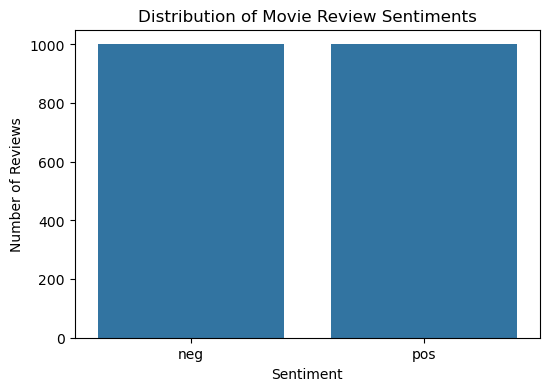

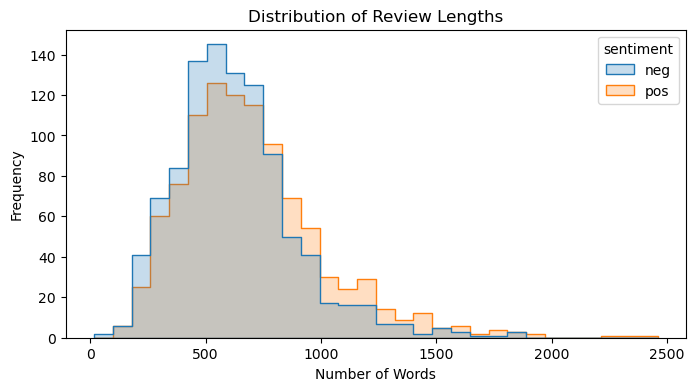

In [7]:

# Part 4: Exploratory Data Analysis (EDA)

# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check for missing values
print("\nMissing values:")
print(df[["review", "sentiment", "clean_review"]].isnull().sum())

# 3. Check sentiment distribution
print("\nSentiment counts:")
print(df["sentiment"].value_counts())

# 4. Calculate review lengths
df["word_count"] = df["clean_review"].apply(
    lambda text: len(text.split())
)

print("\nReview length statistics:")
print(df["word_count"].describe())

# 5. Visualize sentiment distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment")
plt.title("Distribution of Movie Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# 6. Visualize review lengths
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df,
    x="word_count",
    hue="sentiment",
    bins=30,
    element="step"
)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()


In [9]:

# Part 5: Train-Test Split

X = df["clean_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())


Training data: 1600
Testing data: 400

Training sentiment distribution:
sentiment
pos    800
neg    800
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
neg    200
pos    200
Name: count, dtype: int64


In [11]:

# Part 6: TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

# Learn vocabulary from training data and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the SAME learned vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")

print("\nTraining matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("\nFirst 20 vocabulary terms:")
print(tfidf.get_feature_names_out()[:20])


TF-IDF conversion completed!

Training matrix shape: (1600, 10000)
Testing matrix shape: (400, 10000)

First 20 vocabulary terms:
['aaron' 'abandon' 'abandoned' 'abby' 'aberdeen' 'abilities' 'ability'
 'able' 'able make' 'aboard' 'abortion' 'abound' 'abraham' 'absence'
 'absent' 'absolute' 'absolutely' 'absorbed' 'absorbing' 'absurd']


In [17]:

# Part 7: Train Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Model 1: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

# Model 2: Multinomial Naive Bayes
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes training completed!")


Logistic Regression training completed!
Naive Bayes training completed!


In [19]:

# Define the models dictionary

models = {
    "Logistic Regression": lr_model,
    "Naive Bayes": nb_model
}

print("Models dictionary created successfully!")


Models dictionary created successfully!


In [21]:

# Part 9: Predict Sentiment for New Reviews

def predict_sentiment(review):
    # Clean the input review
    cleaned_review = clean_text(review)

    # Convert it using the TF-IDF vectorizer we already fitted
    review_tfidf = tfidf.transform([cleaned_review])

    print("Review:", review)

    # Get predictions from both models
    for name, model in models.items():
        prediction = model.predict(review_tfidf)[0]

        print(f"{name}: {prediction}")

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(review_tfidf)[0]
            probability_map = dict(zip(model.classes_, probabilities))

            print(
                "Positive probability:",
                round(float(probability_map.get("pos", 0)), 3)
            )

    print("-" * 50)


predict_sentiment("This movie was absolutely fantastic and enjoyable!")
predict_sentiment("The film was boring, terrible, and a waste of time.")
predict_sentiment("The acting was good, but the story was disappointing.")


Review: This movie was absolutely fantastic and enjoyable!
Logistic Regression: pos
Positive probability: 0.57
Naive Bayes: pos
Positive probability: 0.614
--------------------------------------------------
Review: The film was boring, terrible, and a waste of time.
Logistic Regression: neg
Positive probability: 0.178
Naive Bayes: neg
Positive probability: 0.124
--------------------------------------------------
Review: The acting was good, but the story was disappointing.
Logistic Regression: neg
Positive probability: 0.454
Naive Bayes: neg
Positive probability: 0.405
--------------------------------------------------


In [23]:

# Part 10: Error Analysis

lr_predictions = lr_model.predict(X_test_tfidf)

error_df = pd.DataFrame({
    "Review": X_test.reset_index(drop=True),
    "Actual": y_test.reset_index(drop=True),
    "Predicted": lr_predictions
})

misclassified = error_df[
    error_df["Actual"] != error_df["Predicted"]
]

print("Total test reviews:", len(X_test))
print("Misclassified reviews:", len(misclassified))
print(
    "Test accuracy:",
    round(accuracy_score(y_test, lr_predictions), 4)
)

display(misclassified.head(10))


Total test reviews: 400
Misclassified reviews: 69
Test accuracy: 0.8275


,Review,Actual,Predicted
3,running time approximately hr mins reviewed by...,neg,pos
10,in the line of duty is the critically praised ...,neg,pos
14,according to popular film opinion a film s gre...,neg,pos
22,the blair witch project was perhaps one of a k...,pos,neg
24,razor blade smile running as part of the vanco...,pos,neg
32,the thirteenth floor is a bland obligatory exe...,neg,pos
34,a couple of criminals mario van peebles and lo...,neg,pos
37,whew this film oozes energy the kind of breakn...,pos,neg
44,mandingo has traditionally been seen as one of...,neg,pos
48,warning may contain some mild spoilers and off...,pos,neg


In [25]:

# Part 11: Save Model Artifacts

import joblib
import os

joblib.dump(lr_model, "sentiment_model.joblib")
joblib.dump(tfidf, "tfidf_vectorizer.joblib")

print("Models saved successfully!")
print("Current directory:", os.getcwd())

print("\nSaved files:")
print(os.path.exists("sentiment_model.joblib"))
print(os.path.exists("tfidf_vectorizer.joblib"))


Models saved successfully!
Current directory: C:\Users\Admin

Saved files:
True
True
